## Ejemplo: tensión hogareña

Cálculo de cuantiles para test de hipótesis

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Ejemplo: tensión hogareña
# cálculo de cuantiles para test de hipótesis
alfa = 0.05
zalfa_2_neg = stats.norm.ppf(alfa / 2)  #cuantil x_{0,025}
zalfa_2_pos = stats.norm.ppf(1 - alfa / 2)  #cuantil x_{0,975}
print('Z_α/2: ', zalfa_2_neg)
print('Z_1-α/2: ', zalfa_2_pos)

Z_α/2:  -1.9599639845400545
Z_1-α/2:  1.959963984540054


Cálculo del número de muestras para cumplir con un beta.

In [2]:
beta = 0.1
zbeta_neg = stats.norm.ppf(beta)
print('Z_β:', zbeta_neg)

# Ejemplo
sigma = 20 / np.sqrt(30)
mu0 = 220   # esperanza de H0
mu1 = 232.0 # esperanza de H1
alpha = 0.05  # probabilidad error tipo I

# Valores críticos
crit = stats.norm.ppf(1 - alpha / 2, loc=mu0, scale=sigma)
crit_neg = stats.norm.ppf(alpha / 2, loc=mu0, scale=sigma)

# Probabilidad de error de tipo II
beta_value = stats.norm.cdf(crit, loc=mu1, scale=sigma) - stats.norm.cdf(crit_neg, loc=mu1, scale=sigma)
print('Probabilidad de error de tipo II (β):', beta_value)

# Potencia del test PI(beta)
power = 1 - beta_value
print('Potencia del test, π(β): ', power)

Z_β: -1.2815515655446004
Probabilidad de error de tipo II (β): 0.09235828257727197
Potencia del test, π(β):  0.907641717422728


Figura que muestra los errores, potencias, etc.

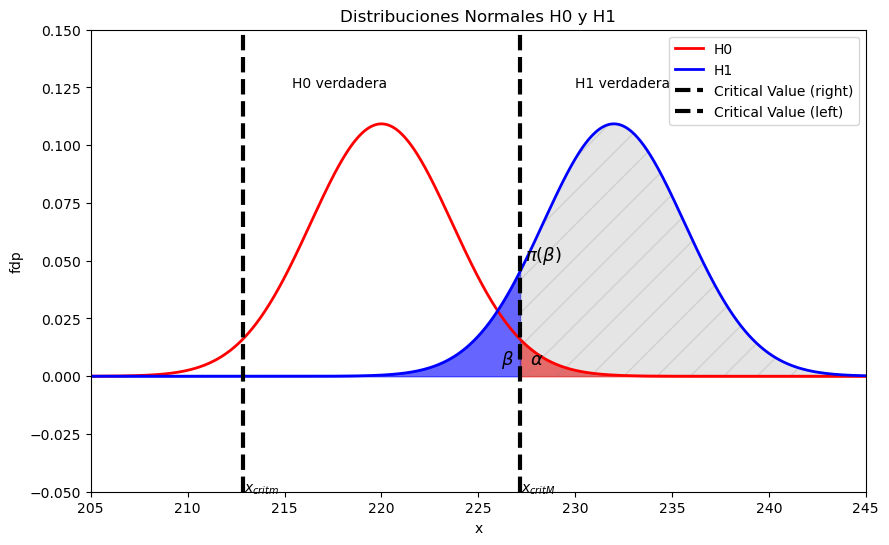

Valor crítico mayor (xcritM): 227.15677657486862
Valor crítico menor (xcritm): 212.84322342513136


In [3]:
# Figura
xLims = [205, 245]
left = np.linspace(xLims[0], crit, 100)
right = np.linspace(crit, xLims[1], 100)
yH0r = stats.norm.pdf(right, mu0, sigma)
yH1l = stats.norm.pdf(left, mu1, sigma)
yH1r = stats.norm.pdf(right, mu1, sigma)

plt.figure(figsize=(10, 6))
x = np.linspace(xLims[0], xLims[1], 1000)
yH0 = stats.norm.pdf(x, mu0, sigma)
yH1 = stats.norm.pdf(x, mu1, sigma)

plt.plot(x, yH0, label='H0', color='red', lw=2)
plt.plot(x, yH1, label='H1', color='blue', lw=2)

plt.fill_between(right, 0, yH0r, color='red', alpha=0.6)
plt.fill_between(left, 0, yH1l, color='blue', alpha=0.6)
plt.fill_between(right, 0, yH1r, color='gray', alpha=0.2, hatch='/')

plt.axvline(x=crit, color='black', linestyle='--', lw=3, label='Critical Value (right)')
plt.axvline(x=crit_neg, color='black', linestyle='--', lw=3, label='Critical Value (left)')

plt.xlim(xLims)
plt.ylim(-0.05, 0.15)
plt.xlabel('x')
plt.ylabel('fdp')
plt.title('Distribuciones Normales H0 y H1')

plt.text(mu0 + 0.3, 0.125, 'H0 verdadera', horizontalalignment='right')
plt.text(mu1 - 2, 0.125, 'H1 verdadera', horizontalalignment='left')
plt.text(crit + 0.25, 0.05, r'$\pi(\beta)$', fontsize=13)
plt.text(crit - 1, 0.005, r'$\beta$', fontsize=13)
plt.text(crit + 0.5, 0.005, r'$\alpha$', fontsize=13)
plt.text(crit + 0.05, -0.05, r'$x_{critM}$', fontsize=10)
plt.text(crit_neg + 0.05, -0.05, r'$x_{critm}$', fontsize=10)

plt.legend()
plt.show()

print('Valor crítico mayor (xcritM):', crit)
print('Valor crítico menor (xcritm):', crit_neg)

## Cálculo de p-valor

Supongamos que el promedio dio: 229.6 V

In [4]:
x_media_observada = (229.6 - mu0) / sigma  # Estandarizo
p_valor = 2 * (1 - stats.norm.cdf(x_media_observada, 0, 1))
print('media observada:', x_media_observada)
print('p-valor:', p_valor)
print(x_media_observada)

#Jugando con n y el p-valor:

# Ejemplo: significancia práctica
mu0 = 220.0
mu1 = 229.6
alpha = 0.05

# Defino una función para calcular p-value y potencia
def calculate_p_value_and_power(n, mu0, mu1, alpha):
    sigma = 20 / np.sqrt(n)
    x_media_observada = (229.6 - mu0) / sigma  # Estandarizo
    p_valor = 2 * (1 - stats.norm.cdf(x_media_observada, 0, 1))
    crit = stats.norm.ppf(1 - alpha / 2, loc=mu0, scale=sigma)
    crit_neg = stats.norm.ppf(alpha / 2, loc=mu0, scale=sigma)
    beta = stats.norm.cdf(crit, loc=mu1, scale=sigma) - stats.norm.cdf(crit_neg, loc=mu1, scale=sigma)
    pow = 1 - beta  # Potencia del test PI(beta)
    print(f'n: {n} ----> p-valor: {p_valor} -----> Potencia: {pow}')

# Tamaños de muestra
sample_sizes = [10, 20, 30, 100]

# Calcular el p-valor para cada uno
for n in sample_sizes:
    calculate_p_value_and_power(n, mu0, mu1, alpha)


media observada: 2.6290682760247956
p-valor: 0.008561916896063781
2.6290682760247956
n: 10 ----> p-valor: 0.12904130509946832 -----> Potencia: 0.3294717397269967
n: 20 ----> p-valor: 0.03182312738649018 -----> Potencia: 0.5740569665465731
n: 30 ----> p-valor: 0.008561916896063781 -----> Potencia: 0.7482877502182744
n: 100 ----> p-valor: 1.586656303897982e-06 -----> Potencia: 0.9977445779714299
